# manasight 03: Color histogram baseline

**Hypothesis H1:** some of a card's color can be read from the *palette* of its art alone.

Notebook 02 showed that the color classes differ on average (red art is warmer, blue art is cooler).
Here we measure how far that goes with a model that sees **only the palette**: which colors of paint are in the
picture and how much of each. It cannot see shapes, objects or where anything is.

Its score is the bar for every later model: whatever a model scores *above* this must come from something
other than the palette.

Sections:
1. Load data
2. The feature: a color histogram
3. What the histogram cannot see
4. Train a simple classifier
5. Test results
6. Which classes work, which do not
7. What the model learned: paint colors per class
8. Slices: without lands, and by era
9. Type from the palette
10. Summary

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from manasight.data import COLOR_CLASSES, COLOR_NAMES, TYPE_CLASSES, load_cards
from manasight.eda import load_thumbnails
from manasight.features import color_histogram
from manasight.evaluate import score

plt.rcParams["figure.dpi"] = 72

## 1. Load data

Same table and the same 32x32 thumbnails as notebook 02. For a palette, a tiny picture is enough:
shrinking a picture keeps its colors.

In [2]:
cards = load_cards()
thumbs, sizes = load_thumbnails(cards)

is_train = (cards.split == "train").to_numpy()
is_val = (cards.split == "val").to_numpy()
is_test = (cards.split == "test").to_numpy()
print(f"train {is_train.sum():,}   val {is_val.sum():,}   test {is_test.sum():,}")

train 35,383   val 4,798   test 3,392


## 2. The feature: a color histogram

Cut each of red, green and blue into 4 levels. That gives 4 x 4 x 4 = **64 color boxes** ("dark red", "light blue",
"mid grey", ...). For every picture we count what share of its pixels falls into each box.
A picture becomes 64 numbers that add up to 1.

features: (48278, 64)


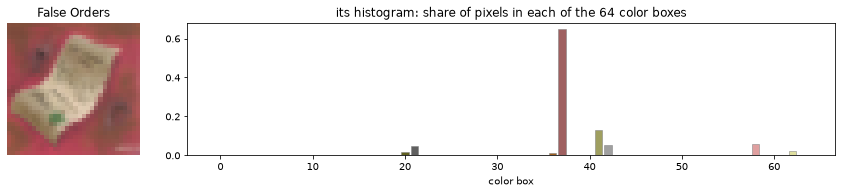

In [3]:
BINS = 4
features = color_histogram(thumbs, bins=BINS)
print("features:", features.shape)

# the color in the middle of every box, to draw the boxes
levels = (np.arange(BINS) + 0.5) / BINS
box_colors = np.array([(r, g, b) for r in levels for g in levels for b in levels])

example = cards.index.get_loc(cards[(cards.split == "train") & (cards.color == "R")].index[5])
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8), gridspec_kw={"width_ratios": [1, 4]})
axes[0].imshow(thumbs[example])
axes[0].set_title(cards.name.iloc[example])
axes[0].axis("off")
axes[1].bar(range(BINS ** 3), features[example], color=box_colors, edgecolor="grey", linewidth=0.5)
axes[1].set_title("its histogram: share of pixels in each of the 64 color boxes")
axes[1].set_xlabel("color box")
plt.tight_layout()
plt.show()

## 3. What the histogram cannot see

Shuffle the pixels of a picture: the content is destroyed, the palette is unchanged.
The histogram is **exactly the same**. So whatever this model scores, it scores without knowing what is in the picture.

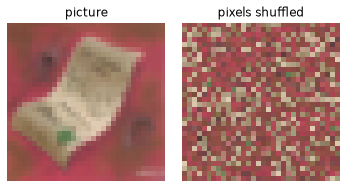

same histogram: True


In [4]:
rng = np.random.RandomState(0)
pixels = thumbs[example].reshape(-1, 3)
shuffled = pixels[rng.permutation(len(pixels))].reshape(thumbs[example].shape)

fig, axes = plt.subplots(1, 2, figsize=(5, 2.6))
axes[0].imshow(thumbs[example])
axes[0].set_title("picture")
axes[1].imshow(shuffled)
axes[1].set_title("pixels shuffled")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

same = (color_histogram(shuffled[None], bins=BINS) == features[example]).all()
print("same histogram:", same)

## 4. Train a simple classifier

**Logistic regression:** one weight per color box and class. It adds up "how much of each paint color" into a
score for every class and picks the highest. Simple on purpose: we are measuring the feature, not the model.

The features are standardized first (every box rescaled to average 0 and spread 1, using the training set only),
so rare colors count as much as common ones.

One choice to check on the **validation** set: 4 levels per channel (64 boxes) or 8 levels (512 boxes)?

In [5]:
for bins in (4, 8):
    x = color_histogram(thumbs, bins=bins)
    scaler_try = StandardScaler().fit(x[is_train])
    model_try = LogisticRegression(max_iter=300).fit(scaler_try.transform(x[is_train]), cards.color[is_train])
    result = score(cards.color[is_val], model_try.predict_proba(scaler_try.transform(x[is_val])), model_try.classes_)
    print(f"{bins} levels ({bins ** 3:3d} boxes)   val accuracy {result['accuracy']:.3f}   macro-F1 {result['macro-F1']:.3f}")

4 levels ( 64 boxes)   val accuracy 0.318   macro-F1 0.290
8 levels (512 boxes)   val accuracy 0.317   macro-F1 0.293


**Finding:** 8 times more boxes changes nothing. A finer palette does not help.

**Decision:** keep 4 levels (64 boxes), the simpler one.

In [6]:
scaler = StandardScaler().fit(features[is_train])
x_train = scaler.transform(features[is_train])
x_val = scaler.transform(features[is_val])
x_test = scaler.transform(features[is_test])

model = LogisticRegression(max_iter=300).fit(x_train, cards.color[is_train])

train_result = score(cards.color[is_train], model.predict_proba(x_train), model.classes_)
val_result = score(cards.color[is_val], model.predict_proba(x_val), model.classes_)
print(f"train accuracy {train_result['accuracy']:.3f}   val accuracy {val_result['accuracy']:.3f}")

train accuracy 0.320   val accuracy 0.318


**Finding:** train and val accuracy are the same. The model is not memorizing anything; with 64 numbers per picture
it simply has no more to learn. This is the ceiling of the palette with a simple model.

## 5. Test results

The 10 held-out sets, used for the first time.

In [7]:
test_cards = cards[is_test]
probabilities = model.predict_proba(x_test)
histogram_result = score(test_cards.color, probabilities, model.classes_)

results = pd.DataFrame([
    {"model": "chance", "accuracy": 1 / 7},
    {"model": "always Multicolor", "accuracy": 0.202, "macro-F1": 0.048},
    {"model": "color histogram (ours)", **histogram_result},
    {"model": "color histogram (reference project)", "accuracy": 0.344},
    {"model": "small CNN from scratch (reference project)", "accuracy": 0.368, "macro-F1": 0.345, "top-2": 0.570},
]).set_index("model")
results.round(3)

,accuracy,macro-F1,top-2
model,,,
chance,0.143,NaN,NaN
always Multicolor,0.202,0.048,NaN
color histogram (ours),0.340,0.304,0.542
color histogram (reference project),0.344,NaN,NaN
small CNN from scratch (reference project),0.368,0.345,0.570


**Finding:** the palette alone gets **34%** of the test cards right, against 20% for the majority guess and 14% by chance.
With two guesses it is right more than half the time. Our number matches the reference project's histogram (34.4%),
which confirms that our data and split behave like the reference setup.

**H1 is supported:** part of a card's color really is in the palette. But two out of three cards are still wrong.

## 6. Which classes work, which do not

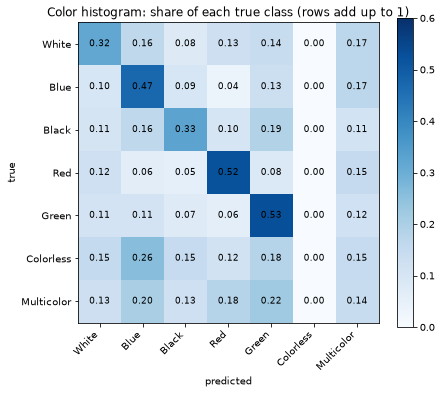

how often each class is predicted:
White         497
Blue          681
Black         432
Red           568
Green         722
Colorless       5
Multicolor    487


In [8]:
predicted = model.classes_[probabilities.argmax(axis=1)]
matrix = confusion_matrix(test_cards.color, predicted, labels=COLOR_CLASSES, normalize="true")

plt.figure(figsize=(6.5, 5.5))
plt.imshow(matrix, cmap="Blues", vmin=0, vmax=0.6)
names = [COLOR_NAMES[c] for c in COLOR_CLASSES]
plt.xticks(range(7), names, rotation=45, ha="right")
plt.yticks(range(7), names)
for row in range(7):
    for column in range(7):
        plt.text(column, row, f"{matrix[row, column]:.2f}", ha="center", va="center", fontsize=9)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("Color histogram: share of each true class (rows add up to 1)")
plt.colorbar()
plt.tight_layout()
plt.show()

print("how often each class is predicted:")
print(pd.Series(predicted).map(COLOR_NAMES).value_counts().reindex(names, fill_value=0).to_string())

**Finding:**
- **Green, Red and Blue** are found about half the time. These are the classes with a palette of their own.
- **White and Black** only a third of the time: "bright" and "dark" are weaker cues than a hue.
- **Colorless is almost never predicted** (5 times in 3,392 cards). **Multicolor** is predicted often but is right
  only 14% of the time. These classes are defined by the rules of the game (no mana color, or several), and they
  have no palette of their own. Their cards get spread over the five colors.

That is where the palette runs out: more than a quarter of the test set (Colorless + Multicolor) is almost invisible to it.

## 7. What the model learned: paint colors per class

Every class has one weight per color box. The boxes with the highest weights are the paint colors that push
the model toward that class.

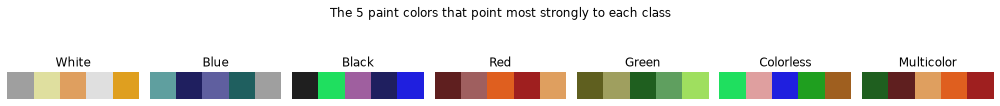

In [9]:
weights = pd.DataFrame(model.coef_, index=model.classes_)

fig, axes = plt.subplots(1, 7, figsize=(14, 1.6))
for ax, color in zip(axes, COLOR_CLASSES):
    best_boxes = weights.loc[color].sort_values(ascending=False).index[:5]
    ax.imshow(box_colors[best_boxes].reshape(1, 5, 3))
    ax.set_title(COLOR_NAMES[color])
    ax.axis("off")
plt.suptitle("The 5 paint colors that point most strongly to each class", y=1.08)
plt.tight_layout()
plt.show()

**Finding:** the model found the color pie by itself: light greys and creams for White, teal and navy for Blue,
near-black for Black, dark reds and orange for Red, olive and dark greens for Green.
For Colorless and Multicolor the top boxes are a mixed bag, which fits section 6.

## 8. Slices: without lands, and by era

all test cards: accuracy 0.340
without lands:  accuracy 0.349   (3,204 cards)


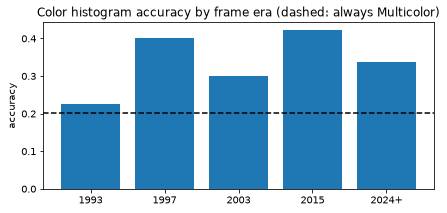

,sets,cards,accuracy,macro-F1,top-2
era,,,,,
1993,"Ice Age, Legends",673,0.224,0.193,0.357
1997,"Invasion, Seventh Edition",662,0.402,0.353,0.594
2003,"Lorwyn, Return to Ravnica",530,0.300,0.259,0.521
2015,"Kamigawa: Neon Dynasty, The Lost Caverns of Ix...",757,0.421,0.375,0.616
2024+,"Aetherdrift, Reality Fracture",770,0.336,0.300,0.604


In [10]:
not_land = ~test_cards.is_land.to_numpy()
no_lands = score(test_cards.color[not_land], probabilities[not_land], model.classes_)
print(f"all test cards: accuracy {histogram_result['accuracy']:.3f}")
print(f"without lands:  accuracy {no_lands['accuracy']:.3f}   ({not_land.sum():,} cards)")

rows = []
for era in ["1993", "1997", "2003", "2015", "2024+"]:
    in_era = (test_cards.era == era).to_numpy()
    result = score(test_cards.color[in_era], probabilities[in_era], model.classes_)
    sets = ", ".join(sorted(test_cards.set_name[in_era].unique()))
    rows.append({"era": era, "sets": sets, "cards": in_era.sum(), **result})
by_era = pd.DataFrame(rows).set_index("era")

plt.figure(figsize=(7, 3))
plt.bar(by_era.index, by_era.accuracy)
plt.axhline(0.202, color="black", linestyle="--")
plt.ylabel("accuracy")
plt.title("Color histogram accuracy by frame era (dashed: always Multicolor)")
plt.show()
by_era.round(3)

**Finding:**
- Lands make almost no difference to the overall score.
- **Era matters a lot.** On the two oldest sets (Ice Age, Legends) the palette barely beats the majority guess.
  Notebook 02 showed that early art is brighter and less vivid: a palette learned mostly from modern art does not
  fit it. The score also swings between newer eras, so the set itself matters (some sets have a strong color look).

This is a first answer to the later question "did the look of the colors change over time?": yes, enough to break a
palette model on the oldest cards.

## 9. Type from the palette

The same features, now predicting the 7 types.

In [11]:
type_model = LogisticRegression(max_iter=300).fit(x_train, cards.type[is_train])
type_probabilities = type_model.predict_proba(x_test)
type_result = score(test_cards.type, type_probabilities, type_model.classes_)
print({name: round(value, 3) for name, value in type_result.items()})

type_predicted = type_model.classes_[type_probabilities.argmax(axis=1)]
print("\nhow often each type is predicted:")
print(pd.Series(type_predicted).value_counts().reindex(TYPE_CLASSES, fill_value=0).to_string())

{'accuracy': 0.498, 'macro-F1': 0.095, 'top-2': 0.608}

how often each type is predicted:
Creature        3384
Planeswalker       0
Land               0
Artifact           1
Enchantment        0
Instant            6
Sorcery            1


**Finding:** the model answers "Creature" for almost every card and scores exactly like the majority guess
(49.8% accuracy, 0.095 macro-F1). The palette carries **no** usable information about type, as notebook 02 suggested
and as the reference project found.

So any type score above the majority guess must come from content. Type is a clean test of whether a model sees
what is in the picture.

## 10. Summary

| Test set, color | Accuracy | Macro-F1 | Top-2 |
|---|---|---|---|
| Chance | 14.3% | | |
| Always Multicolor | 20.2% | 0.048 | |
| **Color histogram** | **34.0%** | **0.304** | **54.2%** |

- **H1 supported:** the palette alone gets about a third of the cards right, 14 points above the majority guess.
- It works for Green, Red and Blue, half-works for White and Black, and fails for Colorless and Multicolor.
- It breaks on the oldest sets (22% on the 1993-era sets).
- A finer palette (512 boxes) does not help, and train = val: this is what the palette has to give.
- The palette says nothing about type.

**The bar for what comes next:** a model that understands content should beat 34% on color clearly, should pick up
Colorless (artifacts are objects) and should beat the majority guess on type.

**Next:** 04, CLIP zero-shot: does a pretrained model that has never seen our labels already know the game's themes?